<a href="https://colab.research.google.com/github/Dex-toxicabyss/tubes-statin-kel1/blob/main/progres_kel_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Besar Statistika Industri
## Analisis Faktor Penentu Angka Harapan Hidup Global (*Life Expectancy WHO*) Tahun 2015

**Program Studi:** S1 Sistem Informasi — Fakultas Rekayasa Industri, Telkom University  
**Kelas:** 25-02 | **Kelompok:** 1  

| No | Nama Lengkap | NIM | Peran Utama |
| :--- | :--- | :---: | :--- |
| 1 | **Raffata Izacky Yuarga Aletama** | `102042500123` | Uji Ulang Normalitas, Visualisasi, & Integrasi |
| 2 | **Muhammad Dyandra Putra** | `102042500152` | *Data Collecting* & *Data Cleansing* |
| 3 | **Muhammad Abyan Setiabudi** | — | Statistika Deskriptif Numerik & Kategorik |
| 4 | **Dustin Alea Maisan** | — | *Stratified Random Sampling* (Slovin) |
| 5 | **Elang Reyfan Bagaskara** | — | Visualisasi & *Heatmap* Korelasi |
| 6 | **Nailah Farah Ramadhani** | — | Deteksi *Outlier* Metode IQR |

---

### Pendahuluan & Rumusan Masalah
Angka harapan hidup (*Life Expectancy*) merupakan indikator makro utama dalam mengevaluasi derajat kesehatan masyarakat dan pembangunan manusia suatu negara. Penelitian ini menggunakan pendekatan *cross-sectional* pada data **World Health Organization (WHO) Tahun 2015** ($N = 183$ negara) untuk menjawab empat rumusan masalah:
1. Bagaimana karakteristik distribusi, pemusatan, penyebaran, serta keberadaan pencilan (*outlier*) pada variabel `Life_expectancy`, `Adult_Mortality`, `GDP`, dan `Schooling` di Tahun 2015?
2. Apakah keempat variabel numerik memenuhi asumsi distribusi normal (Uji Shapiro–Wilk, $\alpha = 0,05$), dan transformasi apa yang paling efektif memperbaiki kenormalannya?
3. Dengan penarikan sampel **Stratified Random Sampling** berukuran Slovin ($n = 126$), apakah sampel representatif terhadap populasi, apakah terdapat perbedaan rata-rata antara negara *Developed* dan *Developing*, serta apakah status negara berhubungan dengan kategori harapan hidup?
4. Seberapa kuat korelasi antarvariabel dan bagaimana persamaan regresi linear sederhana antara lama pendidikan (`Schooling`) terhadap angka harapan hidup (`Life_expectancy`)?

**Sumber Dataset:** [Life Expectancy (WHO) — Kaggle](https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who) | [Raw CSV Mirror (GitHub)](https://raw.githubusercontent.com/Dex-toxicabyss/tubes-statin-kel1/main/Life%20Expectancy%20Data.csv)

---
## 1. Data Collecting, Data Cleaning, Statistika Deskriptif, & Visualisasi

### 1.1 [Dyandra]  *Data Collecting* & *Data Cleansing* (*Cross-Sectional* Tahun 2015)
**Tujuan:** Menyiapkan dataset bersih (`df_clean`) dengan memfokuskan observasi pada **Tahun 2015** agar terhindar dari duplikasi lintas tahun (*panel bias*), memilih 7 variabel penelitian, menghapus duplikat, dan menangani *missing value* pada variabel numerik menggunakan imputasi *mean*.

**Langkah Pengerjaan:**
1. Mengimpor library analisis (`pandas`, `numpy`, `scipy`, `statsmodels`, `matplotlib`, `seaborn`).
2. Memuat dataset mentah dari GitHub (dengan *fallback* file lokal) dan menormalisasi nama kolom.
3. Memfilter baris `Year == 2015` ($N = 183$) dan memeriksa jumlah *missing value* awal (`GDP`: 29 sel kosong; `Schooling`: 10 sel kosong).
4. Menghapus duplikat dan mengimputasi nilai kosong dengan rata-rata (*mean*) kolom masing-masing hingga mencapai **0 nilai kosong**.

In [16]:
# Step 1: Import seluruh library yang dibutuhkan untuk analisis statistik, visualisasi, dan uji normalitas
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import shapiro
from statsmodels.graphics.gofplots import qqplot

# Step 2: Atur resolusi dan tema grafik agar hasil visualisasi rapi dan mudah dibaca
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

# Step 3: Muat dataset Life Expectancy (WHO) dari repository GitHub (dengan fallback file lokal)
url_csv = "https://raw.githubusercontent.com/Dex-toxicabyss/tubes-statin-kel1/main/Life%20Expectancy%20Data.csv"
try:
    df = pd.read_csv(url_csv)
except Exception:
    df = pd.read_csv("Life Expectancy Data.csv")

# Step 4: Rapikan nama kolom dengan menghapus spasi berlebih dan mengganti spasi menjadi underscore (_)
df.columns = df.columns.str.strip().str.replace(' ', '_')

# Step 5: Filter dataset secara cross-sectional khusus Tahun 2015 dan pilih 7 kolom fokus penelitian
df_2015 = df[df['Year'] == 2015].copy()
kolom_fokus = ['Country', 'Year', 'Status', 'Life_expectancy', 'Adult_Mortality', 'GDP', 'Schooling']
df_clean = df_2015[kolom_fokus].copy()

# Step 6: Periksa jumlah baris dan jumlah nilai kosong (NaN) sebelum proses pembersihan
print("=== Kondisi Sebelum Cleansing (Tahun 2015) ===")
print("Jumlah baris awal :", len(df_clean))
print("Nilai kosong awal :\n", df_clean.isna().sum())

# Step 7: Hapus baris duplikat (jika ada) dan lakukan imputasi nilai kosong menggunakan rata-rata (mean) tiap kolom
df_clean = df_clean.drop_duplicates().copy()
kolom_num = ['Life_expectancy', 'Adult_Mortality', 'GDP', 'Schooling']
for col in kolom_num:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mean())

# Step 8: Reset indeks baris dan verifikasi kembali bahwa sudah tidak ada nilai kosong (0 NaN)
df_clean = df_clean.reset_index(drop=True)
print("\n=== Kondisi Setelah Cleansing ===")
print("Dimensi df_clean  :", df_clean.shape)
print("Nilai kosong akhir:\n", df_clean.isna().sum())
display(df_clean.head())

=== Kondisi Sebelum Cleansing (Tahun 2015) ===
Jumlah baris awal : 183
Nilai kosong awal :
 Country             0
Year                0
Status              0
Life_expectancy     0
Adult_Mortality     0
GDP                29
Schooling          10
dtype: int64

=== Kondisi Setelah Cleansing ===
Dimensi df_clean  : (183, 7)
Nilai kosong akhir:
 Country            0
Year               0
Status             0
Life_expectancy    0
Adult_Mortality    0
GDP                0
Schooling          0
dtype: int64


,Country,Year,Status,Life_expectancy,Adult_Mortality,GDP,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,584.259210,10.1
1,Albania,2015,Developing,77.8,74.0,3954.227830,14.2
2,Algeria,2015,Developing,75.6,19.0,4132.762920,14.4
3,Angola,2015,Developing,52.4,335.0,3695.793748,11.4
4,Antigua and Barbuda,2015,Developing,76.4,13.0,13566.954100,13.9


### 1.2 [Abyan]  Statistika Deskriptif Variabel Numerik & Kategorik
**Formulasi Matematis:** Ukuran pemusatan dan penyebaran dihitung menggunakan rata-rata hitung ($\bar{x}$) dan standar deviasi sampel ($s$):
$$\bar{x} = \frac{1}{N} \sum_{i=1}^{N} x_i \quad , \quad s = \sqrt{\frac{\sum_{i=1}^{N} (x_i - \bar{x})^2}{N - 1}} \tag{1}$$

**Langkah Pengerjaan:** Menghitung ringkasan deskriptif global (`count`, `mean`, `std`, `min`, `Q1`, `median`, `Q3`, `max`, `skewness`), distribusi frekuensi kategori `Status` (`Developed` vs `Developing`), serta perbandingan rata-rata dan median antarkelompok status negara.

In [17]:
# Step 1: Hitung statistik deskriptif dasar (count, mean, std, min, Q1, median, Q3, max) untuk variabel numerik
desc_num = df_clean[kolom_num].describe().T

# Step 2: Tambahkan nilai median eksplisit dan skewness (kemencengan distribusi) ke dalam tabel
desc_num['median'] = df_clean[kolom_num].median()
desc_num['skewness'] = df_clean[kolom_num].skew()
print("=== Statistika Deskriptif Variabel Numerik (N = 183) ===")
display(desc_num[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']].round(2))

# Step 3: Hitung frekuensi dan persentase kategori Status negara (Developed vs Developing)
print("\n=== Distribusi Kategori Status Negara ===")
status_counts = df_clean['Status'].value_counts()
status_pct = df_clean['Status'].value_counts(normalize=True) * 100
display(pd.DataFrame({'Jumlah': status_counts, 'Persentase (%)': status_pct.round(2)}))

# Step 4: Bandingkan rata-rata, median, dan standar deviasi antar kelompok negara Developed dan Developing
print("\n=== Perbandingan Rata-Rata Berdasarkan Status ===")
display(df_clean.groupby('Status')[kolom_num].agg(['mean', 'median', 'std']).round(2))

=== Statistika Deskriptif Variabel Numerik (N = 183) ===


,count,mean,std,min,25%,50%,75%,max,skewness
Life_expectancy,183.0,71.62,8.12,51.00,65.75,73.90,76.95,88.00,-0.49
Adult_Mortality,183.0,152.86,97.56,1.00,74.00,138.00,213.00,484.00,0.76
GDP,183.0,7185.33,10725.15,33.68,1152.31,4132.76,7185.33,66346.52,3.12
Schooling,183.0,12.93,2.83,4.90,11.10,12.93,14.85,20.40,-0.23



=== Distribusi Kategori Status Negara ===


,Jumlah,Persentase (%)
Status,,
Developing,151,82.51
Developed,32,17.49



=== Perbandingan Rata-Rata Berdasarkan Status ===


Life_expectancy              Adult_Mortality                \
                      mean median   std            mean median    std   
Status                                                                  
Developed            80.71  81.55  3.46           74.88   64.5  35.85   
Developing           69.69  71.60  7.50          169.39  157.0  98.54   

                 GDP                    Schooling               
                mean   median       std      mean median   std  
Status                                                          
Developed   15278.75  7320.29  16144.14     16.20   16.0  1.90  
Developing   5470.17  3695.79   8292.69     12.23   12.7  2.49

**Interpretasi Hasil (Sub-bab 1.2):**
- Populasi Tahun 2015 ($N = 183$) didominasi negara **Developing** sebanyak **151 negara (82,51%)** dan **Developed** sebanyak **32 negara (17,49%)**.
- Rata-rata `Life_expectancy` global tercatat **71,62 tahun** (median **73,90 tahun**). Negara *Developed* memiliki rata-rata **80,71 tahun**, jauh lebih tinggi dibandingkan negara *Developing* (**69,69 tahun**).
- Variabel `GDP` memiliki standar deviasi (`10.725,15`) lebih besar daripada rata-ratanya (`7.185,33`), menandakan ketimpangan ekonomi antarnegara yang sangat lebar (*right-skewed*).

---

### 1.3 [Nailah]  Deteksi Calon Pencilan (*Outlier*) Menggunakan Metode IQR
**Formulasi Matematis:** Deteksi pencilan menggunakan Rentang Antar-Kuartil (*Interquartile Range*):
$$\text{IQR} = Q_3 - Q_1 \quad ; \quad \text{Batas Bawah} = Q_1 - 1,5 \times \text{IQR} \quad ; \quad \text{Batas Atas} = Q_3 + 1,5 \times \text{IQR} \tag{2}$$

In [18]:
# Step 1: Siapkan list kosong untuk menampung hasil perhitungan batas outlier tiap variabel
ringkasan_iqr = []

# Step 2: Loop setiap variabel numerik untuk menghitung Q1, Q3, IQR, Batas Bawah, dan Batas Atas
for col in kolom_num:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    # Step 3: Saring baris yang nilainya berada di luar rentang [Batas Bawah, Batas Atas] sebagai outlier
    outliers = df_clean[(df_clean[col] < batas_bawah) | (df_clean[col] > batas_atas)]

    # Step 4: Simpan hasil deteksi ke list ringkasan_iqr
    ringkasan_iqr.append({
        'Variabel': col,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Batas_Bawah': round(batas_bawah, 2),
        'Batas_Atas': round(batas_atas, 2),
        'Jumlah_Outlier': len(outliers)
    })

# Step 5: Tampilkan tabel rekapitulasi outlier metode IQR
print("=== Deteksi Outlier Metode IQR (N = 183) ===")
display(pd.DataFrame(ringkasan_iqr))

=== Deteksi Outlier Metode IQR (N = 183) ===


,Variabel,Q1,Q3,IQR,Batas_Bawah,Batas_Atas,Jumlah_Outlier
0,Life_expectancy,65.75,76.95,11.20,48.95,93.75,0
1,Adult_Mortality,74.00,213.00,139.00,-134.50,421.50,1
2,GDP,1152.31,7185.33,6033.02,-7897.22,16234.86,16
3,Schooling,11.10,14.85,3.75,5.47,20.48,3


### 1.4 [Reyfan & Raffata]  Visualisasi Data & *Heatmap* Korelasi (`df_clean`)
**Tujuan:** Mengamati proporsi status negara (*Pie Chart*), kekuatan hubungan linear awal (*Heatmap* Korelasi Pearson), bentuk distribusi `Life_expectancy` (*Histogram + KDE*), dan perbandingan kuartil antarkelompok status (*Boxplot*).

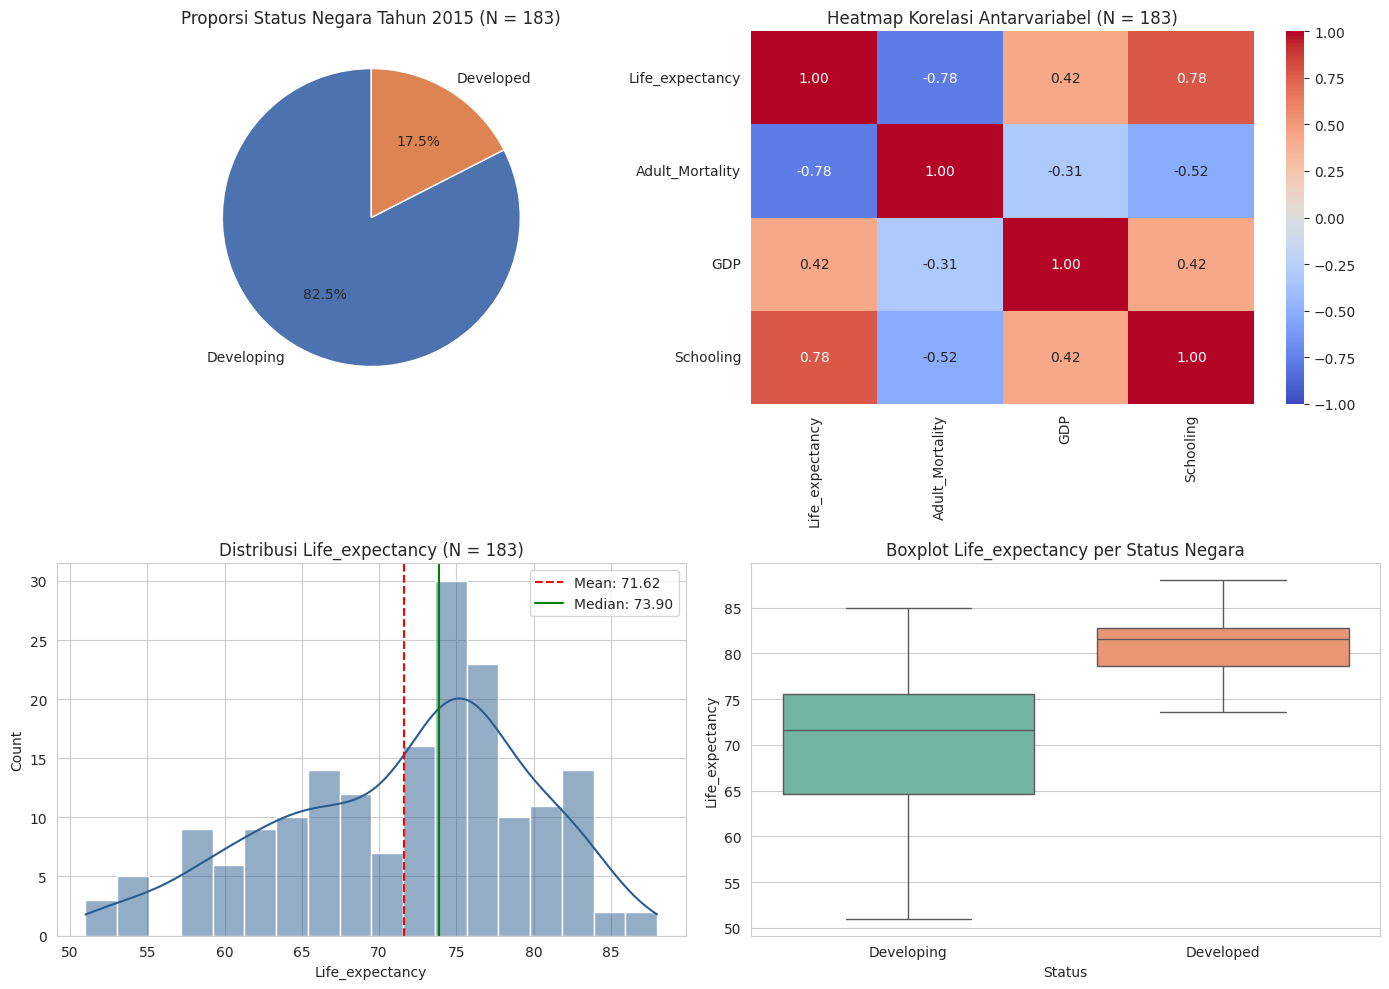

In [19]:
# Step 1: Siapkan kanvas gambar berukuran 2x2 subplot untuk menampilkan 4 visualisasi sekaligus
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Step 2: Buat Pie Chart untuk melihat proporsi negara Developed vs Developing
status_cnt = df_clean['Status'].value_counts()
axes[0, 0].pie(status_cnt, labels=status_cnt.index, autopct='%1.1f%%', startangle=90, colors=['#4C72B0', '#DD8452'])
axes[0, 0].set_title('Proporsi Status Negara Tahun 2015 (N = 183)')

# Step 3: Buat Heatmap Korelasi Pearson untuk melihat hubungan awal antarvariabel numerik
corr_pop = df_clean[kolom_num].corr()
sns.heatmap(corr_pop, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0, 1])
axes[0, 1].set_title('Heatmap Korelasi Antarvariabel (N = 183)')

# Step 4: Buat Histogram + kurva KDE untuk melihat bentuk sebaran Life_expectancy beserta garis Mean & Median
sns.histplot(df_clean['Life_expectancy'], bins=18, kde=True, color='#2b5c8f', ax=axes[1, 0])
axes[1, 0].axvline(df_clean['Life_expectancy'].mean(), color='red', linestyle='--', label=f"Mean: {df_clean['Life_expectancy'].mean():.2f}")
axes[1, 0].axvline(df_clean['Life_expectancy'].median(), color='green', linestyle='-', label=f"Median: {df_clean['Life_expectancy'].median():.2f}")
axes[1, 0].set_title('Distribusi Life_expectancy (N = 183)')
axes[1, 0].legend()

# Step 5: Buat Boxplot untuk membandingkan sebaran kuartil dan outlier Life_expectancy per Status negara
sns.boxplot(data=df_clean, x='Status', y='Life_expectancy', hue='Status', legend=False, palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('Boxplot Life_expectancy per Status Negara')

# Step 6: Rapikan tata letak subplot dan tampilkan seluruh grafik
plt.tight_layout()
plt.show()

---
## 2. Uji Normalitas Data (Shapiro–Wilk, Q–Q Plot, & Transformasi)

### 2.1 Persiapan Data dan Hipotesis Uji Normalitas
- **$H_0$:** Data variabel berasal dari populasi yang berdistribusi normal.
- **$H_1$:** Data variabel tidak berdistribusi normal.
- **Kriteria Keputusan ($\alpha = 0,05$):** Jika $p\text{-value} > 0,05$, maka **Gagal Tolak $H_0$** (normal). Jika $p\text{-value} \le 0,05$, maka **Tolak $H_0$** (tidak normal).

In [31]:
# Step 1: Tentukan daftar 4 variabel numerik yang akan diuji normalitasnya
kolom_uji = ['Life_expectancy', 'Adult_Mortality', 'GDP', 'Schooling']

# Step 2: Tetapkan taraf signifikansi alpha = 0.05 (tingkat kepercayaan 95%)
alpha = 0.05

# Step 3: Verifikasi jumlah baris dan pastikan tidak ada nilai kosong sebelum uji Shapiro-Wilk
print("Jumlah baris:", len(df_clean))
print("Nilai kosong:", df_clean[kolom_uji].isna().sum().to_dict())
print("alpha =", alpha)

Jumlah baris: 183
Nilai kosong: {'Life_expectancy': 0, 'Adult_Mortality': 0, 'GDP': 0, 'Schooling': 0}
alpha = 0.05


### 2.2 Uji Shapiro–Wilk Sebelum Transformasi
Statistik uji Shapiro–Wilk ($W$) mengukur kedekatan kuantil sampel dengan kuantil normal teoretis; nilai $W$ mendekati $1$ mengindikasikan distribusi mendekati normal.

In [21]:
# Step 1: Siapkan list untuk menyimpan hasil uji awal dan daftar variabel yang tidak normal
hasil_awal = []
var_tidak_normal = []

# Step 2: Jalankan uji Shapiro-Wilk untuk setiap variabel pada kolom_uji
for kolom in kolom_uji:
    stat_w, p_val = shapiro(df_clean[kolom])

    # Step 3: Bandingkan p-value dengan alpha = 0.05 untuk menentukan keputusan H0
    keputusan = "Normal (Gagal Tolak H0)" if p_val > alpha else "Tidak Normal (Tolak H0)"
    hasil_awal.append({
        'Variabel': kolom,
        'Min': round(df_clean[kolom].min(), 2),
        'Max': round(df_clean[kolom].max(), 2),
        'Skewness': round(df_clean[kolom].skew(), 3),
        'Statistik_W': round(stat_w, 4),
        'p_value': f"{p_val:.4e}",
        'Keputusan': keputusan
    })

    # Step 4: Catat variabel yang menolak H0 (p-value <= 0.05) untuk ditransformasi pada tahap berikutnya
    if p_val <= alpha:
        var_tidak_normal.append(kolom)

# Step 5: Tampilkan tabel hasil uji Shapiro-Wilk awal
display(pd.DataFrame(hasil_awal))
print("Variabel yang perlu ditransformasi:", var_tidak_normal)

,Variabel,Min,Max,Skewness,Statistik_W,p_value,Keputusan
0,Life_expectancy,51.00,88.00,-0.495,0.9644,1.3318e-04,Tidak Normal (Tolak H0)
1,Adult_Mortality,1.00,484.00,0.764,0.9508,5.7005e-06,Tidak Normal (Tolak H0)
2,GDP,33.68,66346.52,3.121,0.6060,2.7356e-20,Tidak Normal (Tolak H0)
3,Schooling,4.90,20.40,-0.232,0.9915,3.6110e-01,Normal (Gagal Tolak H0)


Variabel yang perlu ditransformasi: ['Life_expectancy', 'Adult_Mortality', 'GDP']


### 2.3 Pembuatan dan Interpretasi Q–Q Plot Sebelum Transformasi
Q–Q Plot memvisualisasikan sebaran kuantil data terhadap garis acuan normal ($45^\circ$). Titik-titik yang menyimpang melengkung di bagian ekor (*tail*) mengonfirmasi ketidaknormalan distribusi.

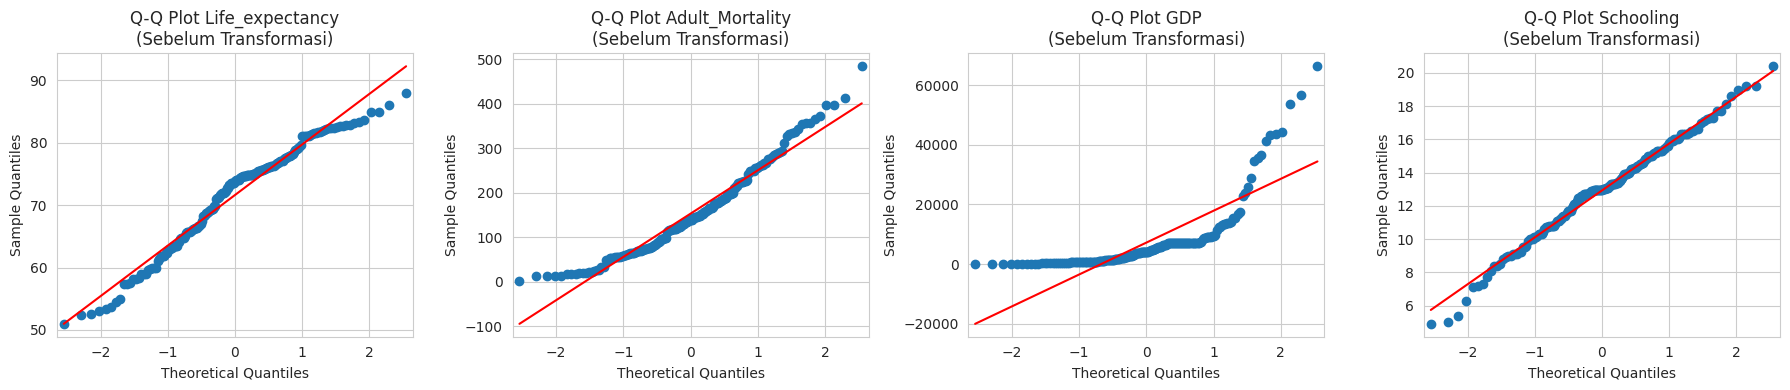

In [22]:
# Step 1: Siapkan 4 subplot mendatar untuk Q-Q Plot keempat variabel sebelum transformasi
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# Step 2: Plot Q-Q Plot tiap variabel terhadap garis acuan distribusi normal (line='s')
for ax, kolom in zip(axes, kolom_uji):
    qqplot(df_clean[kolom], line='s', ax=ax)
    ax.set_title(f'Q-Q Plot {kolom}\n(Sebelum Transformasi)')

# Step 3: Rapikan tata letak dan tampilkan grafik
plt.tight_layout()
plt.show()

### 2.4 Transformasi Variabel yang Tidak Normal
Karena ketiga variabel tidak normal (`Life_expectancy`, `Adult_Mortality`, `GDP`) memiliki nilai minimum $> 0$, maka seluruh kandidat transformasi ($\log_{10}$, $\ln$, $\sqrt{x}$, $x^2$, dan $x^3$) valid untuk dievaluasi.

In [23]:
# Step 1: Buat salinan df_clean agar data asli tetap aman dan tidak tertimpa
df_trans = df_clean.copy()

# Step 2: Siapkan kamus kandidat transformasi untuk masing-masing variabel yang tidak normal
# (Semua nilai min > 0 sehingga transformasi log10, ln, sqrt, dan pangkat valid digunakan)
kandidat_transformasi = {
    'Life_expectancy': {
        'log10': np.log10(df_trans['Life_expectancy']),
        'sqrt': np.sqrt(df_trans['Life_expectancy']),
        'x^2 (kuadrat)': df_trans['Life_expectancy'] ** 2,
        'x^3 (kubik)': df_trans['Life_expectancy'] ** 3,
    },
    'Adult_Mortality': {
        'log10': np.log10(df_trans['Adult_Mortality']),
        'log1p': np.log1p(df_trans['Adult_Mortality']),
        'sqrt': np.sqrt(df_trans['Adult_Mortality']),
    },
    'GDP': {
        'sqrt': np.sqrt(df_trans['GDP']),
        'ln (log)': np.log(df_trans['GDP']),
        'log10': np.log10(df_trans['GDP']),
    }
}

# Step 3: Uji setiap kandidat transformasi menggunakan Shapiro-Wilk dan catat nilai W serta p-value
hasil_eksperimen = []
for kolom in var_tidak_normal:
    for metode, seri in kandidat_transformasi[kolom].items():
        w_t, p_t = shapiro(seri)
        hasil_eksperimen.append({
            'Variabel': kolom,
            'Metode': metode,
            'Skewness_sesudah': round(seri.skew(), 3),
            'W_sesudah': round(w_t, 4),
            'p_sesudah': f"{p_t:.4e}",
            'Status_alpha_0.05': 'Normal (Gagal Tolak H0)' if p_t > alpha else 'Masih Tolak H0'
        })

# Step 4: Tampilkan tabel perbandingan seluruh kandidat transformasi
display(pd.DataFrame(hasil_eksperimen))

# Step 5: Simpan kolom hasil transformasi terbaik (nilai W tertinggi) ke dalam df_trans
df_trans['Life_expectancy_cube'] = df_trans['Life_expectancy'] ** 3
df_trans['Adult_Mortality_sqrt'] = np.sqrt(df_trans['Adult_Mortality'])
df_trans['GDP_log10'] = np.log10(df_trans['GDP'])

,Variabel,Metode,Skewness_sesudah,W_sesudah,p_sesudah,Status_alpha_0.05
0,Life_expectancy,log10,-0.730,0.9455,1.8805e-06,Masih Tolak H0
1,Life_expectancy,sqrt,-0.611,0.9559,1.7444e-05,Masih Tolak H0
2,Life_expectancy,x^2 (kuadrat),-0.269,0.9760,2.9945e-03,Masih Tolak H0
3,Life_expectancy,x^3 (kubik),-0.052,0.9804,1.1156e-02,Masih Tolak H0
4,Adult_Mortality,log10,-1.532,0.8975,6.4193e-10,Masih Tolak H0
5,Adult_Mortality,log1p,-1.289,0.9153,8.8270e-09,Masih Tolak H0
6,Adult_Mortality,sqrt,-0.039,0.9920,4.1345e-01,Normal (Gagal Tolak H0)
7,GDP,sqrt,1.451,0.8744,3.1621e-11,Masih Tolak H0
8,GDP,ln (log),-0.573,0.9629,9.0534e-05,Masih Tolak H0
9,GDP,log10,-0.573,0.9629,9.0534e-05,Masih Tolak H0


### 2.5 [RAFFATA]  Uji Ulang Shapiro Wilk dan Perbandingan Q–Q Plot
Membandingkan statistik $W$, $p$-value, dan pola Q–Q Plot sebelum vs sesudah transformasi terpilih.

,Variabel,Metode,W_Sebelum,p_Sebelum,W_Sesudah,p_Sesudah,Keputusan_Sesudah
0,Life_expectancy,x^3 (Kubik),0.9644,1.3318e-04,0.9804,1.1156e-02,Masih Menolak H0 (p <= 0.05)
1,Adult_Mortality,sqrt (Akar Kuadrat),0.9508,5.7005e-06,0.9920,4.1345e-01,Normal (Gagal Tolak H0)
2,GDP,log10,0.6060,2.7356e-20,0.9629,9.0534e-05,Masih Menolak H0 (p <= 0.05)


- Life_expectancy -> x^3 (Kubik): Distribusi awal left-skewed (-0.495); x^3 menaikkan W (0.9644 -> 0.9804), namun masih menolak H0 (p <= 0.05).
- Adult_Mortality -> sqrt (Akar Kuadrat): Distribusi awal right-skewed (+0.764); sqrt menormalkan distribusi hingga gagal tolak H0 (W = 0.9920, p = 0.4135 > 0.05).
- GDP -> log10: Distribusi awal sangat right-skewed (+3.121); log10 menaikkan W sebesar +0.3569 (0.6060 -> 0.9629), namun masih menolak H0 (p <= 0.05).


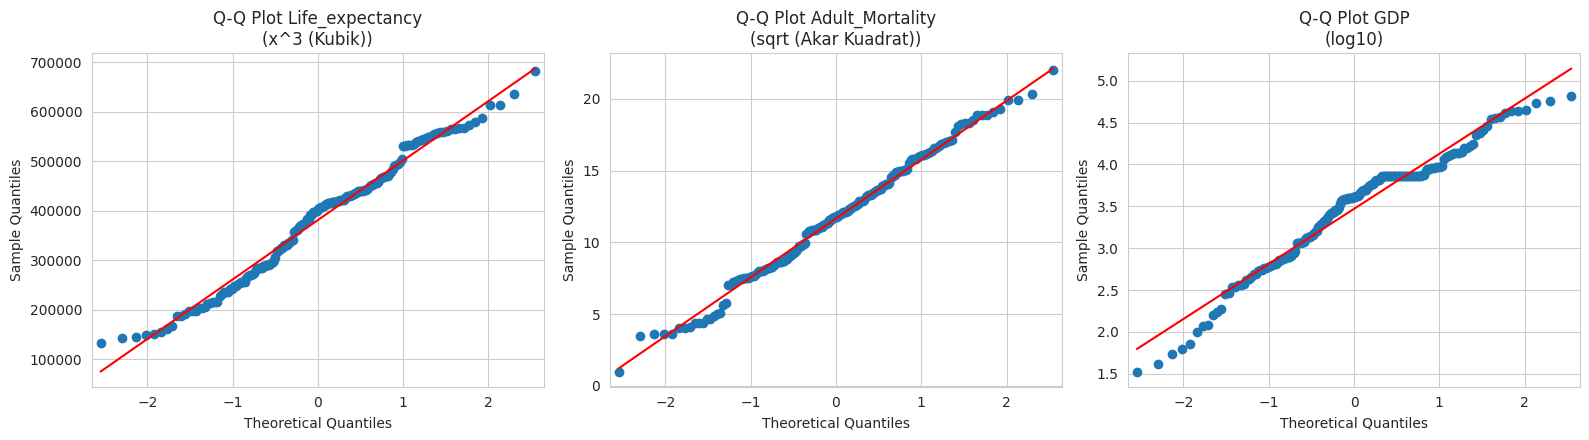

In [24]:
# Step 1: Definisikan metode transformasi terpilih beserta alasan pemilihannya
pilihan_transformasi = [
    {
        'kolom_asli': 'Life_expectancy',
        'kolom_trans': 'Life_expectancy_cube',
        'metode': 'x^3 (Kubik)',
        'alasan': 'Distribusi awal left-skewed (-0.495); x^3 menaikkan W (0.9644 -> 0.9804), namun masih menolak H0 (p <= 0.05).'
    },
    {
        'kolom_asli': 'Adult_Mortality',
        'kolom_trans': 'Adult_Mortality_sqrt',
        'metode': 'sqrt (Akar Kuadrat)',
        'alasan': 'Distribusi awal right-skewed (+0.764); sqrt menormalkan distribusi hingga gagal tolak H0 (W = 0.9920, p = 0.4135 > 0.05).'
    },
    {
        'kolom_asli': 'GDP',
        'kolom_trans': 'GDP_log10',
        'metode': 'log10',
        'alasan': 'Distribusi awal sangat right-skewed (+3.121); log10 menaikkan W sebesar +0.3569 (0.6060 -> 0.9629), namun masih menolak H0 (p <= 0.05).'
    }
]

# Step 2: Bandingkan statistik W dan p-value sebelum vs sesudah transformasi untuk tiap variabel
baris_perbandingan = []
for item in pilihan_transformasi:
    w_sblm, p_sblm = shapiro(df_clean[item['kolom_asli']])
    w_ssdh, p_ssdh = shapiro(df_trans[item['kolom_trans']])
    baris_perbandingan.append({
        'Variabel': item['kolom_asli'],
        'Metode': item['metode'],
        'W_Sebelum': round(w_sblm, 4),
        'p_Sebelum': f"{p_sblm:.4e}",
        'W_Sesudah': round(w_ssdh, 4),
        'p_Sesudah': f"{p_ssdh:.4e}",
        'Keputusan_Sesudah': 'Normal (Gagal Tolak H0)' if p_ssdh > alpha else 'Masih Menolak H0 (p <= 0.05)'
    })

# Step 3: Tampilkan tabel perbandingan dan catatan alasan pemilihan transformasi
display(pd.DataFrame(baris_perbandingan))
for item in pilihan_transformasi:
    print(f"- {item['kolom_asli']} -> {item['metode']}: {item['alasan']}")

# Step 4: Buat Q-Q Plot sesudah transformasi untuk memverifikasi kelurusan titik terhadap garis normal
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, item in zip(axes, pilihan_transformasi):
    qqplot(df_trans[item['kolom_trans']], line='s', ax=ax)
    ax.set_title(f"Q-Q Plot {item['kolom_asli']}\n({item['metode']})")
plt.tight_layout()
plt.show()

### 2.6 Penyimpanan Dataset Final (`df_final`)
Menggabungkan seluruh kolom asli `df_clean` dengan ketiga kolom hasil transformasi terpilih menjadi `df_final` (`183 x 10`) dan mengekspornya ke `Life_Expectancy_2015_Transformed.csv`.

In [25]:
# Step 1: Buat df_final dari salinan df_clean agar kolom identitas dan data asli tetap terjaga
df_final = df_clean.copy()

# Step 2: Tambahkan ketiga kolom hasil transformasi terpilih ke dalam df_final
df_final['Life_expectancy_cube'] = df_trans['Life_expectancy_cube']
df_final['Adult_Mortality_sqrt'] = df_trans['Adult_Mortality_sqrt']
df_final['GDP_log10'] = df_trans['GDP_log10']

# Step 3: Periksa dimensi akhir dan pastikan tidak ada nilai kosong (0 NaN)
print("Dimensi df_final:", df_final.shape)
print("Nilai kosong:", df_final.isna().sum().sum())

# Step 4: Ekspor dataset final ke format CSV tanpa indeks baris
nama_file_output = 'Life_Expectancy_2015_Transformed.csv'
df_final.to_csv(nama_file_output, index=False)
print(f"Dataset diekspor ke: {nama_file_output}")

Dimensi df_final: (183, 10)
Nilai kosong: 0
Dataset diekspor ke: Life_Expectancy_2015_Transformed.csv


---
## 3. Pemilihan Sampel (*Stratified Random Sampling*  Rumus Slovin)

### 3.1 [Dustin]  Penentuan Ukuran & Penarikan Sampel Proporsional
**Justifikasi Pemilihan Metode:** Populasi Tahun 2015 ($N = 183$) memiliki dua strata kategori `Status` yang tidak seimbang: **Developed** ($32$ negara; $17,49\%$) dan **Developing** ($151$ negara; $82,51\%$). Oleh karena itu, digunakan ***Stratified Random Sampling* Proporsional** agar komposisi negara maju dan berkembang dalam sampel tetap sama persis dengan populasinya, sehingga menjamin validitas uji 1 sampel, uji beda 2 sampel, uji Chi-Square, dan regresi linear pada tahap selanjutnya.

**Formulasi Matematis (Slovin, $e = 5\%$):**
$$n = \left\lceil \frac{N}{1 + N \cdot e^2} \right\rceil = \left\lceil \frac{183}{1 + 183(0,05)^2} \right\rceil = 126 \text{ negara} \tag{3}$$
- **Strata `Developed` ($n_1$):** $\text{round}\left(126 \times \frac{32}{183}\right) = 22$ negara
- **Strata `Developing` ($n_2$):** $126 - 22 = 104$ negara

In [26]:
# Step 1: Tetapkan ukuran populasi N dari df_clean dan margin of error e = 5% (0.05)
N = len(df_clean)
e = 0.05

# Step 2: Hitung total ukuran sampel minimal menggunakan rumus Slovin dan bulatkan ke atas
n = min(math.ceil(N / (1 + N * (e ** 2))), N)

# Step 3: Hitung alokasi ukuran sampel proporsional untuk masing-masing strata Status (Developed vs Developing)
pop_dev = df_clean[df_clean['Status'] == 'Developed']
pop_devg = df_clean[df_clean['Status'] == 'Developing']

n_dev = round(n * (len(pop_dev) / N))
n_devg = n - n_dev

# Step 4: Tarik sampel acak dari tiap strata tanpa pengembalian dengan random_state=42 agar reproducible
sampel_dev = pop_dev.sample(n=n_dev, replace=False, random_state=42)
sampel_devg = pop_devg.sample(n=n_devg, replace=False, random_state=42)

# Step 5: Gabungkan kedua strata menjadi df_sampel dan reset indeks baris
df_sampel = pd.concat([sampel_dev, sampel_devg], ignore_index=True)

# Step 6: Tampilkan ringkasan proporsi strata dan 5 baris pertama df_sampel
print(f"Populasi (N)             : {N} (Developed={len(pop_dev)}, Developing={len(pop_devg)})")
print(f"Ukuran sampel Slovin (n) : {n} ({len(df_sampel) / N:.2%} dari populasi)")
print(f"Alokasi Strata Sampel    : Developed={n_dev} ({n_dev/n:.2%}), Developing={n_devg} ({n_devg/n:.2%})")
display(df_sampel.head())

Populasi (N)             : 183 (Developed=32, Developing=151)
Ukuran sampel Slovin (n) : 126 (68.85% dari populasi)
Alokasi Strata Sampel    : Developed=22 (17.46%), Developing=104 (82.54%)


,Country,Year,Status,Life_expectancy,Adult_Mortality,GDP,Schooling
0,Switzerland,2015,Developed,83.4,49.0,8989.84240,16.0
1,Lithuania,2015,Developed,73.6,165.0,14252.42853,16.5
2,Singapore,2015,Developed,83.1,55.0,53629.73746,15.4
3,Malta,2015,Developed,81.7,54.0,23819.46360,14.6
4,Germany,2015,Developed,81.0,68.0,41176.88158,17.1


---
## 4. Uji Hipotesis & Uji Chi-Square (Sampel *Stratified* Slovin $n = 126$)

### 4.1 Uji Hipotesis Menyangkut Rata-Rata (1-Sample & 2-Sample *t-test*)
1. **Uji 1 Sampel (Validasi Representativitas Sampel):**
   - $H_0: \mu_{\text{sampel}} = \mu_{\text{populasi}}$ ($71,62$ tahun)
   - $H_1: \mu_{\text{sampel}} \ne 71,62$ tahun
2. **Uji 2 Sampel Independen (Welch's *t-test*, Varians Tidak Diasumsikan Sama):**
   - $H_0: \mu_{\text{Developed}} = \mu_{\text{Developing}}$
   - $H_1: \mu_{\text{Developed}} \ne \mu_{\text{Developing}}$

In [27]:
# Step 1: Hitung rata-rata populasi (df_clean) sebagai nilai acuan mu_0 untuk menguji representativitas sampel
mu_pop = df_clean['Life_expectancy'].mean()
mean_le = df_sampel['Life_expectancy'].mean()

# Step 2: Uji Hipotesis 1 Sampel (dua arah) -> H0: mu_sampel = mu_populasi vs H1: mu_sampel != mu_populasi
t_stat1, p_val1 = stats.ttest_1samp(df_sampel['Life_expectancy'], popmean=mu_pop, alternative='two-sided')

print("=== Uji Hipotesis 1 Sampel (Representativitas Sampel vs Populasi) ===")
print(f"Mean Populasi (mu_0): {mu_pop:.4f} tahun")
print(f"Mean Sampel (x_bar) : {mean_le:.4f} tahun")
print(f"t-statistik         : {t_stat1:.4f}")
print(f"p-value             : {p_val1:.4f}")
print("Keputusan           :", "Gagal Tolak H0 (sampel representatif terhadap populasi)" if p_val1 > alpha else "Tolak H0 (berbeda signifikan)")

# Step 3: Pisahkan data sampel Life_expectancy menjadi kelompok Developed dan Developing
grup_dev = df_sampel[df_sampel['Status'] == 'Developed']['Life_expectancy']
grup_devg = df_sampel[df_sampel['Status'] == 'Developing']['Life_expectancy']

# Step 4: Uji Hipotesis 2 Sampel Independen (Welch's t-test) untuk membandingkan rata-rata kedua kelompok
t_stat2, p_val2 = stats.ttest_ind(grup_dev, grup_devg, equal_var=False)

print("\n=== Uji Hipotesis 2 Sampel (Developed vs Developing) ===")
print(f"Developed (n={len(grup_dev)})   : Mean = {grup_dev.mean():.4f}")
print(f"Developing (n={len(grup_devg)}) : Mean = {grup_devg.mean():.4f}")
print(f"t-statistik : {t_stat2:.4f}")
print(f"p-value     : {p_val2:.4e}")
print("Keputusan   :", "Tolak H0 (ada perbedaan signifikan)" if p_val2 <= alpha else "Gagal Tolak H0")

=== Uji Hipotesis 1 Sampel (Representativitas Sampel vs Populasi) ===
Mean Populasi (mu_0): 71.6169 tahun
Mean Sampel (x_bar) : 71.5476 tahun
t-statistik         : -0.0960
p-value             : 0.9237
Keputusan           : Gagal Tolak H0 (sampel representatif terhadap populasi)

=== Uji Hipotesis 2 Sampel (Developed vs Developing) ===
Developed (n=22)   : Mean = 80.5682
Developing (n=104) : Mean = 69.6394
t-statistik : 10.1303
p-value     : 7.5242e-15
Keputusan   : Tolak H0 (ada perbedaan signifikan)


**Interpretasi Hasil (Sub-bab 4.1):**
- **Uji 1 Sampel:** Rata-rata `Life_expectancy` sampel (`71,55 tahun`) sangat dekat dengan rata-rata populasi (`71,62 tahun`) dengan $t = -0,0960$ dan $p = 0,9237 > 0,05$ (**Gagal Tolak $H_0$**), membuktikan *Stratified Random Sampling* menghasilkan sampel yang sangat representatif.
- **Uji 2 Sampel:** Terdapat perbedaan yang sangat signifikan antara rata-rata harapan hidup negara *Developed* (`80,57 tahun`) dan *Developing* (`69,64 tahun`) dengan selisih **10,93 tahun** ($t = 10,1303$; $p = 7,52 \times 10^{-15} < 0,05$).

---

### 4.2 Uji Chi-Square Independensi
**Tujuan & Hipotesis:** Menguji apakah kategori status ekonomi negara (`Status`) berhubungan dengan kategori tinggi/rendahnya harapan hidup (`Kategori_LE`) berdasarkan **Median Populasi ($73,90$ tahun)**:
$$\chi^2 = \sum \frac{(O_i - E_i)^2}{E_i} \tag{4}$$
- **$H_0$:** `Status` negara dan `Kategori_LE` saling independen (tidak ada hubungan).
- **$H_1$:** Terdapat hubungan signifikan antara `Status` negara dan `Kategori_LE`.

In [28]:
# Step 1: Gunakan Median populasi (df_clean) sebagai batas alami pembagian kategori tinggi vs rendah
med_pop = df_clean['Life_expectancy'].median()
df_sampel['Kategori_LE'] = np.where(
    df_sampel['Life_expectancy'] >= med_pop,
    f'Tinggi (>={med_pop:.1f})',
    f'Rendah (<{med_pop:.1f})'
)

# Step 2: Bentuk tabel kontingensi (silang) antara Status Negara dan Kategori_LE
tabel_kontingensi = pd.crosstab(df_sampel['Status'], df_sampel['Kategori_LE'])

# Step 3: Jalankan uji Chi-Square Independensi untuk mendapatkan statistik chi2, p-value, df, dan frekuensi harapan
chi2, p_chi, dof, expected = stats.chi2_contingency(tabel_kontingensi)

# Step 4: Tampilkan tabel kontingensi, hasil uji, dan verifikasi syarat minimum expected frequency >= 5
print(f"=== Tabel Kontingensi (Batas Median Populasi = {med_pop:.2f} tahun) ===")
display(tabel_kontingensi)
print(f"Chi-Square (chi2) : {chi2:.4f}")
print(f"Derajat bebas (df): {dof}")
print(f"Min Expected Freq : {expected.min():.2f} (>= 5, syarat terpenuhi)")
print(f"p-value           : {p_chi:.4e}")
print("Keputusan         :", "Tolak H0 (ada hubungan signifikan)" if p_chi <= alpha else "Gagal Tolak H0")

=== Tabel Kontingensi (Batas Median Populasi = 73.90 tahun) ===


Kategori_LE,Rendah (<73.9),Tinggi (>=73.9)
Status,,
Developed,1,21
Developing,63,41


Chi-Square (chi2) : 20.6229
Derajat bebas (df): 1
Min Expected Freq : 10.83 (>= 5, syarat terpenuhi)
p-value           : 5.5922e-06
Keputusan         : Tolak H0 (ada hubungan signifikan)


---
## 5. Korelasi & Regresi Linear Sederhana (Sampel *Stratified* $n = 126$)

### 5.1 Matriks Korelasi Pearson & *Heatmap*
Mengukur arah dan kekuatan hubungan linear ($r \in [-1, +1]$) antarvariabel numerik pada sampel representatif (`df_sampel`, $n = 126$).

=== Matriks Korelasi Pearson (Sampel n = 126) ===


,Life_expectancy,Adult_Mortality,GDP,Schooling
Life_expectancy,1.0000,-0.7748,0.4634,0.7703
Adult_Mortality,-0.7748,1.0000,-0.3435,-0.5193
GDP,0.4634,-0.3435,1.0000,0.4882
Schooling,0.7703,-0.5193,0.4882,1.0000


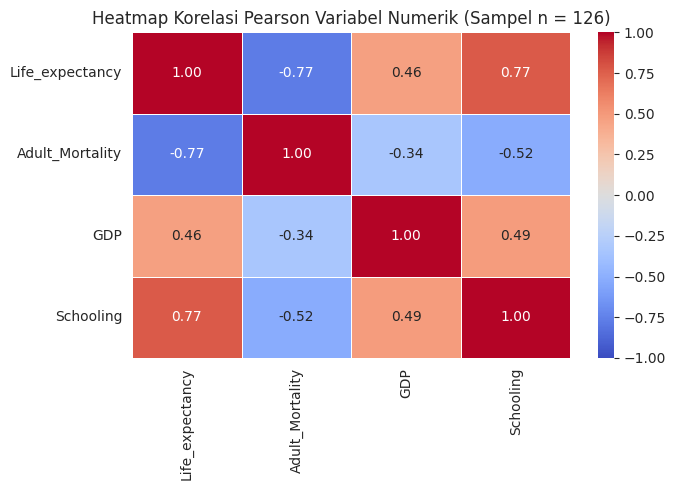

In [29]:
# Step 1: Hitung matriks korelasi Pearson antarvariabel numerik menggunakan data sampel (n = 126)
matriks_corr = df_sampel[kolom_num].corr(method='pearson')

# Step 2: Tampilkan nilai matriks korelasi dalam bentuk tabel
print("=== Matriks Korelasi Pearson (Sampel n = 126) ===")
display(matriks_corr.round(4))

# Step 3: Visualisasikan matriks korelasi ke dalam Heatmap agar pola hubungan mudah diamati
plt.figure(figsize=(7, 5))
sns.heatmap(matriks_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap Korelasi Pearson Variabel Numerik (Sampel n = 126)')
plt.tight_layout()
plt.show()

### 5.2 Regresi Linear Sederhana ($\hat{Y} = aX + b$)
**Formulasi Model:** Memodelkan pengaruh variabel independen $X = \text{Schooling}$ (lama pendidikan formal, tahun) terhadap variabel dependen $Y = \text{Life\_expectancy}$ (angka harapan hidup, tahun):
$$\hat{Y} = aX + b \tag{5}$$
di mana $a$ (*slope*) menyatakan perubahan rata-rata $Y$ untuk setiap kenaikan 1 tahun $X$, dan $b$ (*intercept*) adalah nilai dasar $Y$ ketika $X = 0$.

=== Hasil Regresi Linear Sederhana (Y = aX + b) ===
Persamaan Regresi       : Y = 2.2143 * X + 42.9519
Korelasi (r)            : 0.7703
Koefisien Determinasi R2: 0.5934 (59.34% variasi Y dijelaskan oleh X)
p-value                 : 5.4058e-26
Contoh Prediksi (X=12)  : Y = 69.52 tahun


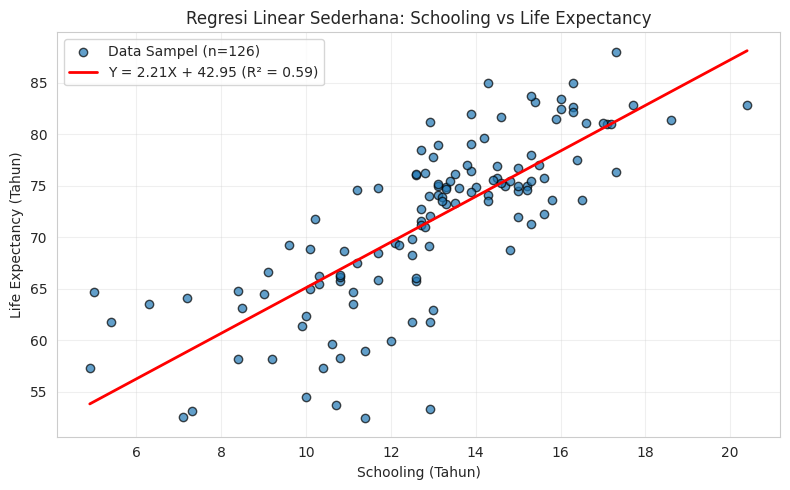

In [30]:
# Step 1: Tetapkan variabel independen X (Schooling) dan variabel dependen Y (Life_expectancy)
X = df_sampel['Schooling']
Y = df_sampel['Life_expectancy']

# Step 2: Hitung model regresi linear sederhana Y = aX + b menggunakan scipy.stats.linregress
reg = stats.linregress(X, Y)
a, b = reg.slope, reg.intercept
r_val, r2_val, p_reg = reg.rvalue, reg.rvalue ** 2, reg.pvalue

# Step 3: Tampilkan persamaan regresi, nilai R-squared, p-value, dan contoh prediksi untuk X = 12 tahun
print("=== Hasil Regresi Linear Sederhana (Y = aX + b) ===")
print(f"Persamaan Regresi       : Y = {a:.4f} * X + {b:.4f}")
print(f"Korelasi (r)            : {r_val:.4f}")
print(f"Koefisien Determinasi R2: {r2_val:.4f} ({r2_val:.2%} variasi Y dijelaskan oleh X)")
print(f"p-value                 : {p_reg:.4e}")
print(f"Contoh Prediksi (X=12)  : Y = {a * 12 + b:.2f} tahun")

# Step 4: Buat Scatter Plot data sampel beserta garis lurus model regresi linearnya
plt.figure(figsize=(8, 5))
plt.scatter(X, Y, alpha=0.7, edgecolors='k', label='Data Sampel (n=126)')
x_line = np.linspace(X.min(), X.max(), 100)
plt.plot(x_line, a * x_line + b, color='red', linewidth=2, label=f'Y = {a:.2f}X + {b:.2f} (R² = {r2_val:.2f})')
plt.title('Regresi Linear Sederhana: Schooling vs Life Expectancy')
plt.xlabel('Schooling (Tahun)')
plt.ylabel('Life Expectancy (Tahun)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## 6. Kesimpulan & Daftar Pustaka

### 6.1 Kesimpulan Akhir (Tahun 2015, Populasi $N = 183$, Sampel *Stratified* $n = 126$)
1. **Pembersihan & Deskriptif:** Dataset bersih Tahun 2015 terdiri dari $N = 183$ negara (0 nilai kosong setelah imputasi *mean* pada `GDP` dan `Schooling`), dengan rata-rata harapan hidup global **71,62 tahun** (*Developed* 80,71 tahun vs *Developing* 69,69 tahun).
2. **Uji Normalitas & Transformasi:** Pada uji awal Shapiro–Wilk ($\alpha = 0,05$), hanya `Schooling` yang normal ($p = 0,3611$). Setelah transformasi, `Adult_Mortality` ($\sqrt{x}$) menjadi normal ($p = 0,4135$), sementara `Life_expectancy` ($x^3$, $W = 0,9804$) dan `GDP` ($\log_{10}$, $W = 0,9629$) meningkat signifikan namun masih menolak $H_0$.
3. **Sampling & Uji Inferensial:** *Stratified Random Sampling* Slovin ($n = 126$: 22 *Developed*, 104 *Developing*) terbukti sangat representatif terhadap rata-rata populasi ($\bar{x} = 71,55$ vs $\mu_0 = 71,62$; $t = -0,0960; p = 0,9237 > 0,05$). Uji 2 sampel membuktikan kesenjangan signifikan sebesar **10,93 tahun** antara *Developed* (**80,57 th**) dan *Developing* (**69,64 th**) ($t = 10,1303; p = 7,52 \times 10^{-15}$), dan uji Chi-Square mengonfirmasi hubungan signifikan antara Status Negara dan kategori harapan hidup berbasis median $73,90$ tahun ($\chi^2 = 20,6229; p = 5,59 \times 10^{-6}$).
4. **Korelasi & Regresi Linear:** `Schooling` berkorelasi positif kuat dengan `Life_expectancy` ($r = 0,7703$), dengan model regresi $\hat{Y} = 2,2143X + 42,9519$ ($R^2 = 0,5934; p = 5,41 \times 10^{-26}$). Setiap kenaikan 1 tahun lama pendidikan formal berasosiasi dengan peningkatan angka harapan hidup sekitar **2,21 tahun**.

### 6.2 Daftar Pustaka
1. Rajarshi, K., Russell, D., & Wang, D. (2018). *Life Expectancy (WHO): Statistical Analysis on Factors Influencing Life Expectancy*. Kaggle / WHO. https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who
2. Aji, C. (2022). *Exploratory Data Analysis (EDA) – Life Expectancy WHO Dataset*. RPubs. https://rpubs.com/chaidaraji/eda-life-expectancy
3. Kar, N. G. (2022). *Life Expectancy Statistical Analysis (WHO)*. RStudio Pubs. https://rstudio-pubs-static.s3.amazonaws.com/920150_6696a808906844cb98fc53a6c31d6999.html